# CSVから作るストリーク画像（軸方向位置 × 時間）

指定した半径のプロファイルを全保存時刻で並べ、横軸 **時間 [ns]**・縦軸 **z [mm]** のストリーク画像を描きます。
**Pythonカーネル**で上から実行します。必要なパッケージは `numpy`, `matplotlib` です。

- 参考Notebookの励起種 `N₂(C)`・`N₂⁺(B)` は現在のCSVにはありません。このNotebookでは **電子密度・電位・軸方向換算電場の絶対値** を表示します。発光強度や視線積分画像を計算するものではありません。
- `RADIUS_MM = 0` は最も軸に近いセルを選びます。標準格子では実際の半径は **5 μm** で、r=0への外挿はしません。
- CSVはC互換の `(r,z)` 順で復元します。`Ey` が軸方向の換算電場で、単位は既にTdです。
- 時刻は **step × DT_SECONDS**。電位・電場は各stepの密度更新前、電子密度は更新後の値です。
- NaN・無限大・読めないフレームは白く表示し、その時間列は保持します。電子密度のゼロ・負値も対数図では白くします。
- 縦軸は参考と同じく反転を既定にしています。座標が増える方向を上にするには `INVERT_Z_AXIS=False` に変更します。

入力CSV・画像保存先の相対パスは、このNotebookの場所ではなく、`Project.toml` があるプロジェクト直下が基準です。

In [7]:
from pathlib import Path
import re

import numpy as np
import matplotlib.pyplot as plt

# ---- 変更する設定 ----
INPUT_DIR = Path("outputdata_impulse")  # outputdata_notebook / outputdata_short など
DT_SECONDS = 1.0e-12                   # 計算に使ったdt [s]
RADIUS_MM = 0.0                        # 最も近い半径のセルを選択 [mm]
FIELDS = ("ne", "phi", "abs_ez")       # ne / phi / abs_ez / ez / magnitude / er
TIME_LIMITS_NS = None                  # 例: (0.0, 5.0)
Z_LIMITS_MM = None                     # 例: (0.0, 1.0)
INVERT_Z_AXIS = True
COLOR_LIMITS = {"ne": (14.0, 22.0)}     # neはlog10値。未指定の量は有限値から自動設定
# COLOR_LIMITS["abs_ez"] = (0.0, 600.0) # 電場の色範囲 [Td]
SAVE_RESULTS = True
EXPORT_DIR = Path("figures")

## CSVを読み、位置×時間の行列を作る

`INPUT_DIR` はプロジェクトからの相対パス、または絶対パスです。プロジェクト内か、その親フォルダから実行できます。
保存先ごとに異なる格子や計算条件を混在させないでください。設定値はCSVに含まれないため、時間刻みは計算時の値に合わせます。
表示する量のファイルからstep番号の和集合を作り、欠けたファイルはその時刻の列を欠損値として残します。

In [8]:
# Notebookのフォルダ・プロジェクト直下・親フォルダのどこからでも実行できるようにする。
PROJECT_DIR = next(
    (candidate.resolve()
     for base in (Path.cwd(), *Path.cwd().parents)
     for candidate in (base, base / "streamer_python")
     if (candidate / "streamer_drift_diffusion").is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("streamer_python project not found")
import sys
sys.path.insert(0, str(PROJECT_DIR))
from streamer_drift_diffusion.output import load_output_times
project = PROJECT_DIR
input_dir = INPUT_DIR if INPUT_DIR.is_absolute() else project / INPUT_DIR
export_dir = EXPORT_DIR if EXPORT_DIR.is_absolute() else project / EXPORT_DIR
if not np.isfinite(DT_SECONDS) or DT_SECONDS <= 0:
    raise ValueError("DT_SECONDSは正の有限値にしてください。")
if not np.isfinite(RADIUS_MM) or RADIUS_MM < 0:
    raise ValueError("RADIUS_MMは0以上の有限値にしてください。")

specs = {
    "ne": ("ne", r"Electron density $\log_{10}(n_e\,[\mathrm{m}^{-3}])$", "viridis"),
    "phi": ("phi", r"Potential $\phi$ [V]", "magma"),
    "abs_ez": ("Ey", r"Axial reduced field $|E_z|/N$ [Td]", "jet"),
    "ez": ("Ey", r"Axial reduced field $E_z/N$ [Td]", "coolwarm"),
    "magnitude": ("absE", r"Reduced field $|\mathbf{E}|/N$ [Td]", "jet"),
    "er": ("Ex", r"Radial reduced field $E_r/N$ [Td]", "coolwarm"),
}
if not FIELDS or any(field not in specs for field in FIELDS):
    raise ValueError(f"FIELDSは{tuple(specs)}から1個以上選んでください。")
fields = tuple(dict.fromkeys(FIELDS))


def load_coordinate(name):
    values = np.atleast_1d(np.loadtxt(input_dir / name))
    if (values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all()
            or np.any(np.diff(values) <= 0)):
        raise ValueError(f"{name}は昇順で2点以上の有限な座標にしてください。")
    return values * 1e3  # m → mm


r_mm = load_coordinate("rh.csv")
z_mm = load_coordinate("zh.csv")
nr, nz = len(r_mm), len(z_mm)
if RADIUS_MM > r_mm[-1]:
    raise ValueError(f"RADIUS_MMが最大セル中心半径 {r_mm[-1]:g} mmを超えています。")
radial_index = int(np.argmin(np.abs(r_mm - RADIUS_MM)))
prefixes = tuple(dict.fromkeys(specs[field][0] for field in fields))
step_set = set()
for prefix in prefixes:
    pattern = re.compile(rf"^{re.escape(prefix)}(\d+)\.csv$")
    step_set.update(int(m.group(1)) for p in input_dir.glob(f"{prefix}*.csv")
                    if (m := pattern.fullmatch(p.name)))
steps = np.array(sorted(step_set), dtype=int)
if steps.size == 0:
    raise FileNotFoundError(f"表示する量のCSVがありません: {input_dir}")
time_ns = load_output_times(input_dir, steps, DT_SECONDS) * 1e9

raw = {}
problems = []
for prefix in prefixes:
    matrix = np.full((nz, len(steps)), np.nan)
    for column, step in enumerate(steps):
        path = input_dir / f"{prefix}{step}.csv"
        try:
            values = np.atleast_1d(np.loadtxt(path))
            if values.ndim != 1 or values.size != nr * nz:
                raise ValueError(f"shape={values.shape}, expected {nr * nz} values")
            profile = values.reshape((nr, nz), order="C")[radial_index, :].copy()
            profile[~np.isfinite(profile)] = np.nan
            matrix[:, column] = profile
        except (OSError, ValueError) as exc:
            problems.append((path.name, str(exc)))  # 欠けた時間列を詰めない
    raw[prefix] = matrix

# 保存用は物理量の値を保持し、表示用の電子密度だけlog10へ変換する。
data = {field: (np.abs(raw[specs[field][0]]) if field == "abs_ez"
                else raw[specs[field][0]].copy()) for field in fields}
plot_data = {}
for field, matrix in data.items():
    if field == "ne":
        with np.errstate(divide="ignore", invalid="ignore"):
            plot_data[field] = np.where(matrix > 0, np.log10(matrix), np.nan)
    else:
        plot_data[field] = matrix
if not any(np.isfinite(a).any() for a in plot_data.values()):
    raise ValueError("選択した半径のデータに、描画できる値がありません。")

print(f"Input: {input_dir}")
print(f"Radius: {r_mm[radial_index]:g} mm; grid: {nr} × {nz}")
print(f"Frames: {len(steps)}; time labels: {time_ns[0]:g}–{time_ns[-1]:g} ns")
for field, matrix in plot_data.items():
    valid = matrix[np.isfinite(matrix)]
    span = f"{valid.min():.5g} to {valid.max():.5g}" if valid.size else "no valid values"
    print(f"{field}: plot range {span}; blank points: {matrix.size - valid.size}")
if problems:
    print(f"Unreadable/missing files: {len(problems)} (columns left blank)")
    for name, reason in problems[:5]:
        print(f"  {name}: {reason}")
if len(steps) == 1:
    print("1時刻のみです。進展の比較には複数時刻のCSVが必要です。")

Input: C:\Users\daiko\Documents\Python_venvSystem\3.14system\streamer_julia\streamer_julia\outputdata_impulse
Radius: 0.005 mm; grid: 200 × 100
Frames: 51; time labels: 0–5 ns
ne: plot range 13 to 21.398; blank points: 0
phi: plot range 0.78612 to 4863.4; blank points: 0
abs_ez: plot range 6.427 to 556.68; blank points: 0


## ストリーク画像を描画・保存する

列が時刻、行がz位置です。`ne` の色は常用対数、その他は元の単位を使用します。
非有限値を補間せず白く表示します。色範囲の未指定項目は表示可能な全値から設定します。
画像はPNG・PDF、抽出した数値はNPZで保存します。ファイル名には入力フォルダと半径を付けます。同名ファイルは上書きします。
NPZの軸は `time_ns`, `z_mm`、物理量は `FIELDS` の名前です。`ne` は対数化前の数密度を保存し、負値も診断用に残します。

Saved: C:\Users\daiko\Documents\Python_venvSystem\3.14system\streamer_julia\streamer_julia\figures\streak_outputdata_impulse_r0.005mm.png
Saved: C:\Users\daiko\Documents\Python_venvSystem\3.14system\streamer_julia\streamer_julia\figures\streak_outputdata_impulse_r0.005mm.pdf
Saved: C:\Users\daiko\Documents\Python_venvSystem\3.14system\streamer_julia\streamer_julia\figures\streak_outputdata_impulse_r0.005mm.npz


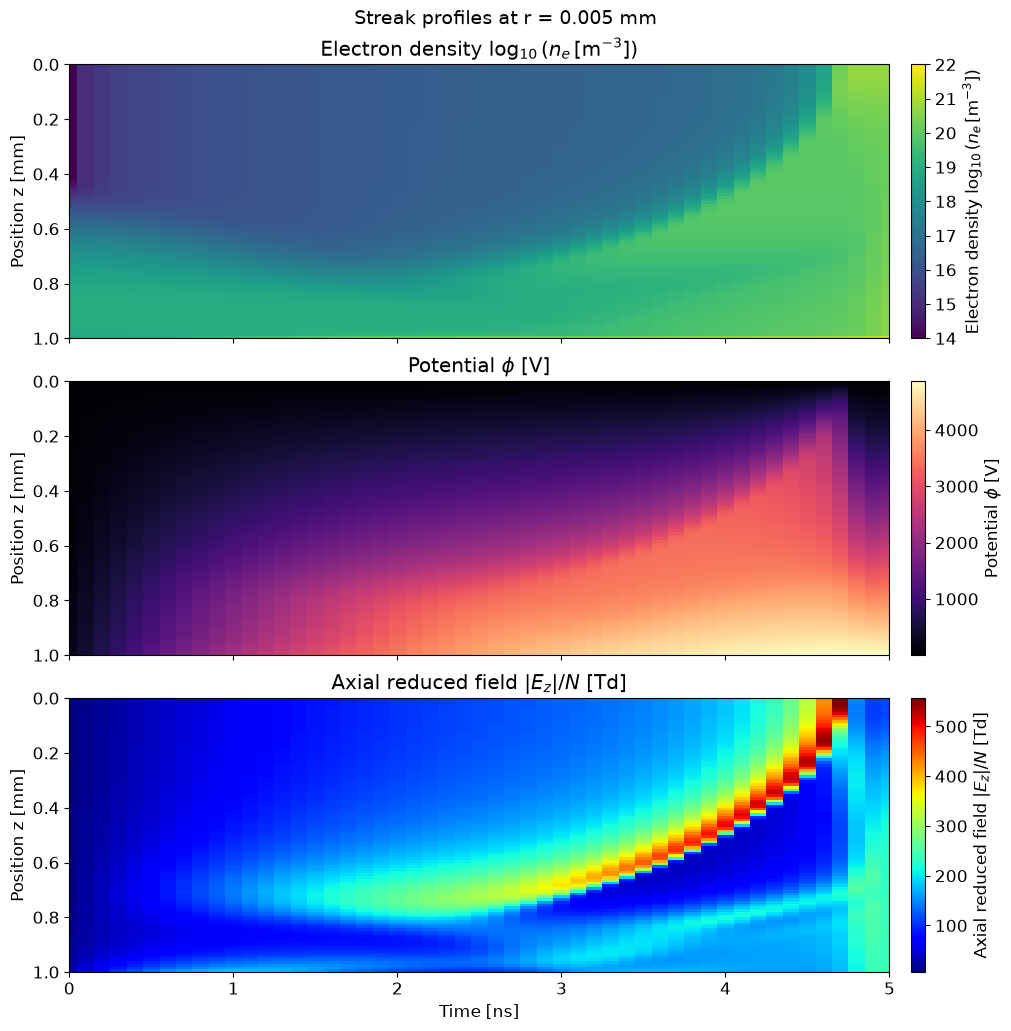

In [9]:
def cell_edges(centers, single_width):
    # 時刻が1点のときも1列のセルとして表示できるよう端点を作る。
    if len(centers) == 1:
        return np.array([centers[0] - single_width / 2, centers[0] + single_width / 2])
    mid = (centers[:-1] + centers[1:]) / 2
    return np.r_[centers[0] - (mid[0] - centers[0]), mid,
                 centers[-1] + (centers[-1] - mid[-1])]


t_edges = cell_edges(time_ns, DT_SECONDS * 1e9)
z_edges = cell_edges(z_mm, float(np.diff(z_mm).min()))
with plt.rc_context({"font.size": 12, "pdf.fonttype": 42}):
    fig, axes = plt.subplots(len(fields), 1, figsize=(10, 3.4 * len(fields)),
                             sharex=True, squeeze=False, layout="constrained")
    for ax, field in zip(axes[:, 0], fields):
        _, label, cmap_name = specs[field]
        matrix = plot_data[field]
        valid = matrix[np.isfinite(matrix)]
        limits = COLOR_LIMITS.get(field)
        if limits is None:
            lo, hi = (float(valid.min()), float(valid.max())) if valid.size else (0.0, 1.0)
            if lo == hi:
                hi = lo + max(1.0, abs(lo) * 0.01)
        else:
            lo, hi = limits
            if not np.isfinite([lo, hi]).all() or lo >= hi:
                raise ValueError(f"{field}の色範囲は有限な下限<上限にしてください。")
        cmap = plt.get_cmap(cmap_name).copy()
        cmap.set_bad("white")
        image = ax.pcolormesh(t_edges, z_edges, np.ma.masked_invalid(matrix),
                              shading="flat", cmap=cmap, vmin=lo, vmax=hi,
                              rasterized=True)
        ax.set_title(label + (" (no valid data)" if not valid.size else ""))
        ax.set_ylabel("Position z [mm]")
        ax.set_ylim(Z_LIMITS_MM if Z_LIMITS_MM is not None else (z_edges[0], z_edges[-1]))
        if INVERT_Z_AXIS:
            ax.invert_yaxis()
        fig.colorbar(image, ax=ax, label=label, pad=0.02)
    axes[-1, 0].set_xlabel("Time [ns]")
    default_time_limits = (time_ns[0], time_ns[-1]) if len(steps) > 1 else (t_edges[0], t_edges[-1])
    axes[-1, 0].set_xlim(TIME_LIMITS_NS if TIME_LIMITS_NS is not None else default_time_limits)
    fig.suptitle(f"Streak profiles at r = {r_mm[radial_index]:g} mm", fontsize=14)
    if SAVE_RESULTS:
        export_dir.mkdir(parents=True, exist_ok=True)
        stem = f"streak_{input_dir.name}_r{r_mm[radial_index]:g}mm"
        for extension in ("png", "pdf"):
            path = export_dir / f"{stem}.{extension}"
            fig.savefig(path, dpi=180, bbox_inches="tight")
            print(f"Saved: {path}")
        path = export_dir / f"{stem}.npz"
        np.savez_compressed(path, time_ns=time_ns, z_mm=z_mm, steps=steps,
                            radius_mm=r_mm[radial_index], dt_seconds=DT_SECONDS,
                            input_dir=str(input_dir), **data)
        print(f"Saved: {path}")
    plt.show()